# Titanic Dataset: Production Pipeline, Model Tuning & Explainability

## Executive Summary
This notebook represents the second phase of the end-to-end Machine Learning pipeline for the RMS Titanic disaster prediction. Building on the statistical diagnostics and domain transformations established during exploratory profiling, this phase transitions the solution from experimentation into a modular, production-ready architecture.

The core objectives of this notebook are:
1. **Encapsulate an End-to-End Leakage-Free Pipeline (`TitanicDataPipeline`)**: Implement a reproducible data transformer adhering to the `fit`/`transform` contract. Imputation statistics and encoding dimensions are learned strictly on training partitions, and features are partitioned into dedicated model matrices (`linear` and `trees`).
2. **Standardize Cross-Validation Benchmarking (`TitanicExperimentRunner`)**: Establish out-of-fold stratified evaluation across diverse model families (Logistic Regression, Random Forest), ensuring scaling and feature transformations remain isolated per fold.
3. **Automate Hyperparameter Optimization (`TitanicOptunaTuner`)**: Conduct Bayesian optimization via Optuna (TPE Sampler) over defined search spaces to locate optimal regularization and tree pruning configurations.
4. **Deploy Production Inference Artifacts (`TitanicPredictor`)**: Bundle the trained estimators, frozen preprocessors, scalers, and decision thresholds into serializable runtime artifacts (`joblib`) capable of both single-record and batch payload execution.
5. **Model Explainability & Feature Attribution (`SHAP`)**: Deconstruct individual predictions using TreeSHAP waterfall plots to diagnose exact feature contributions, quantify marginal impacts, and inspect the internal decision paths of the model for specific passenger profiles.

---

## Tech Stack & Architecture
* **Data Processing & Pipelines**: `pandas`, `numpy`, `scikit-learn` (`StandardScaler`, `StratifiedKFold`)
* **Model Families**: `LogisticRegression`, `RandomForestClassifier`
* **Bayesian Optimization**: `optuna` (TPE sampler, Stratified OOF validation)
* **Model Explainability**: `shap` (TreeExplainer, Waterfall plots)
* **Production Packaging & I/O**: `joblib`

In [1]:
import copy
import joblib
import numpy as np
import optuna
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

### 1. Data Pipeline Architecture (`TitanicDataPipeline`)

To guarantee strict encapsulation and prevent data leakage during cross-validation and inference, all transformations are formalized within the `TitanicDataPipeline` class adhering to a standard `fit`/`transform` interface.

#### Key Engineering Decisions
* **Strict Training Encapsulation (`fit`)**: Subgroup statistics—hierarchical age medians (`Title` × `Pclass`), ticket frequency counts, `FarePerPerson` class medians, and the empirical `Embarked` mode—are learned exclusively from the training fold and stored in instance state.
* **Layered Fallback Imputation**: During `transform`, missing values are imputed hierarchically:
  $$\text{Age: } \text{Median(Title, Pclass)} \longrightarrow \text{Median(Title)} \longrightarrow \text{Global Median}$$
  $$\text{Fare: } \text{Median(Pclass)} \longrightarrow \text{Global Median}$$
* **Out-of-Fold Frequency Resolution**: For group size estimation, ticket frequencies on unseen test/validation batches combine frozen training frequencies with local batch occurrences, preventing shape mismatches on unseen tickets.
* **Dual Matrix Splitting**: Based on the collinearity diagnostics and distribution audits established in the preceding `01_Data_analysis` notebook, the pipeline bifurcates the feature space into two specialized matrices:
  * `X_linear` (20 features): Employs log-transformed fares (`LogFarePerPerson`), removes continuous `GroupSize` in favor of discretized cohorts, and drops explicit reference levels across all categorical dummies to eliminate multicollinearity and prevent dummy variable trap singularities.
  * `X_trees` (25 features): Retains the full one-hot dummy representation, preserves raw `FarePerPerson`, and keeps orthogonal categorical splits to maximize partition efficiency in recursive decision trees.

In [2]:
class TitanicDataPipeline:
    """Production-ready feature engineering and preprocessing pipeline for the Titanic dataset.
    
    Learns imputation statistics, encodings, and frequencies exclusively on training data
    to prevent data leakage, and transforms raw passenger data into dedicated feature
    matrices tailored for linear estimators and tree-based models.
    """

    def __init__(self):
        """Initializes internal state containers for fitted statistics and schema definitions."""
        # Parameters taught on training set
        self.age_medians = {}
        self.age_title_medians = {}
        self.age_global_median = None
        self.fare_pp_medians = {}
        self.fare_pp_global_median = None
        self.embarked_mode = None
        self.ticket_counts = {}

        # One hot columns
        self.linear_columns = None
        self.tree_columns = None

        # Title list - not included become 'Rare'
        self.title_mapping = {
            'Mr': 'Mr',
            'Miss': 'Miss',
            'Mrs': 'Mrs',
            'Master': 'Master',
            'Mlle': 'Miss',
            'Ms': 'Miss',
            'Mme': 'Mrs',
        }

    def _extract_titles(self, names: pd.Series) -> pd.Series:
        """Parses honorific titles from passenger name strings using regex.

        Args:
            names: Pandas Series containing raw passenger names.

        Returns:
            Pandas Series of mapped, standardized categorical titles.
        """
        return (
            names.str.extract(r',\s*([^\.]+)\.', expand=False)
            .map(self.title_mapping)
            .fillna('Rare')
        )

    def fit(self, df_train: pd.DataFrame):
        """Fits preprocessing statistics strictly on training data to prevent leakage.

        Computes hierarchical age medians, ticket frequencies, class-level
        fare-per-person medians, and the empirical Embarked mode.

        Args:
            df_train: Raw training DataFrame containing target and predictor features.

        Returns:
            self: The fitted pipeline instance.
        """
        df = df_train.copy()

        # Executing method for title extraction
        df['Title'] = self._extract_titles(df['Name'])

        # 1. Age median (Title+Pclass -> Title -> Global)
        self.age_medians = (
            df.groupby(['Title', 'Pclass'])['Age'].median().to_dict()
        )
        self.age_title_medians = df.groupby('Title')['Age'].median().to_dict()
        self.age_global_median = df['Age'].median()

        # 2. Ticket fare median, based on FarePerPerson with groupsize calculation
        self.ticket_counts = df['Ticket'].value_counts().to_dict()

        family_size = df['SibSp'] + df['Parch'] + 1
        ticket_size = df['Ticket'].map(self.ticket_counts).fillna(1)
        df['GroupSize'] = np.maximum(family_size, ticket_size)

        df['FarePerPerson'] = df['Fare'] / df['GroupSize']
        self.fare_pp_medians = (
            df.groupby('Pclass')['FarePerPerson'].median().to_dict()
        )
        self.fare_pp_global_median = df['FarePerPerson'].median()

        # 3. Boarding place dominant
        self.embarked_mode = df['Embarked'].mode()[0]

        return self

    def _engineer_features(
        self, df_input: pd.DataFrame, is_train: bool = False
    ) -> pd.DataFrame:
        """Applies imputation, grouping, transformation, and column pruning.

        Args:
            df_input: Input DataFrame with target/id columns already removed.
            is_train: Flag indicating whether transformation occurs on training fold.

        Returns:
            Preprocessed DataFrame with engineered features ready for encoding.
        """
        df = df_input.copy()

        # 1. Titles extraction and mapping via _extract_titles method
        df['Title'] = self._extract_titles(df['Name'])

        # 2. Age imputation, using previously calculated data
        age_lookup = df[['Title', 'Pclass']].apply(tuple, axis=1)
        df['Age'] = (
            df['Age']
            .astype(float)
            .fillna(age_lookup.map(self.age_medians).astype(float))
            .fillna(df['Title'].map(self.age_title_medians).astype(float))
            .fillna(float(self.age_global_median))
        )

        # 3. Group size calculation - based on ticket and family
        family_size = df['SibSp'] + df['Parch'] + 1
        if is_train:
            ticket_size = df['Ticket'].map(self.ticket_counts).fillna(1)
        else:
            train_occurences = df['Ticket'].map(self.ticket_counts).fillna(0)
            batch_occurences = (
                df['Ticket'].map(df['Ticket'].value_counts()).fillna(0)
            )

            ticket_size = (train_occurences + batch_occurences).clip(lower=1)

        df['GroupSize'] = np.maximum(family_size, ticket_size)
        df['GroupType'] = pd.cut(
            df['GroupSize'],
            bins=[0, 1, 4, np.inf],
            labels=['Alone', 'SmallGroup', 'LargeGroup'],
        )

        # 4. Embarked imputation
        df['Embarked'] = df['Embarked'].fillna(self.embarked_mode)

        # 5. FarePerPerson imputation - based on previously calculated groupsize
        df['FarePerPerson'] = df['Fare'] / df['GroupSize']
        df['FarePerPerson'] = (
            df['FarePerPerson']
            .fillna(df['Pclass'].map(self.fare_pp_medians))
            .fillna(self.fare_pp_global_median)
        )
        df['LogFarePerPerson'] = np.log1p(df['FarePerPerson'])

        # 6. Decks and cabins
        df['HasCabin'] = df['Cabin'].notna().astype(int)
        df['Deck'] = df['Cabin'].str[0].fillna('U').replace({'T': 'A'})

        # 7. Dropping raw data and used for calculations columns
        drop_cols = [
            'Name',
            'Ticket',
            'Cabin',
            'Fare',
            'SibSp',
            'Parch',
            'Sex',
        ]  # Dropping sex because of redundacy with titles
        df = df.drop(
            columns=[c for c in drop_cols if c in df.columns], errors='ignore'
        )

        return df

    def transform(self, df_input: pd.DataFrame, is_train: bool = False):
        """Transforms raw input records into specialized feature matrices.

        Executes end-to-end feature engineering, one-hot encoding, model-specific
        column filtering, and schema alignment (reindexing).

        Args:
            df_input: Raw passenger DataFrame to be transformed.
            is_train: If True, registers the resulting feature column schema;
                      if False, aligns columns to frozen training schema.

        Returns:
            X_linear: Feature DataFrame optimized for linear estimators (20 columns).
            X_trees: Feature DataFrame optimized for tree-based models (25 columns).
            passenger_ids: Numpy array of passenger IDs, or None if not present.
        """
        df = df_input.copy()

        # Keeping Ids in separate variable - not used for training, later to be added to model predictions
        passenger_ids = (
            df['PassengerId'].values if 'PassengerId' in df.columns else None
        )

        # Dropping Ids column and target feature
        cols_to_remove = [
            c
            for c in ['PassengerId', 'Survived']
            if c
            in df.columns  # No error, no need for defense? To be explained in markdown desc
        ]
        df = df.drop(columns=cols_to_remove)

        # Feature Engineering
        df_fe = self._engineer_features(df, is_train=is_train)

        # One-Hot Encoding
        df_encoded = pd.get_dummies(
            df_fe,
            columns=['Pclass', 'Title', 'GroupType', 'Embarked', 'Deck'],
            dtype=int,
        )

        # Preparing set for linear models
        cols_drop_linear = [
            'FarePerPerson',
            'GroupSize',
            'Pclass_1',
            'Title_Mr',
            'GroupType_Alone',
            'Embarked_S',
            'Deck_U',
        ]
        X_linear = df_encoded.drop(
            columns=[
                c for c in cols_drop_linear if c in df_encoded.columns
            ].copy()
        )

        # Preparing set for tree based models
        cols_drop_trees = ['LogFarePerPerson', 'Deck_U']
        X_trees = df_encoded.drop(
            columns=[
                c for c in cols_drop_trees if c in df_encoded.columns
            ].copy()
        )

        # Fitting sets to the same shape
        if is_train:
            self.linear_columns = X_linear.columns.tolist()
            self.tree_columns = X_trees.columns.tolist()
        else:
            X_linear = X_linear.reindex(
                columns=self.linear_columns, fill_value=0
            )
            X_trees = X_trees.reindex(columns=self.tree_columns, fill_value=0)

        return X_linear, X_trees, passenger_ids

In [3]:
#Loading datasets
df_train_raw = pd.read_csv('Titanic-Dataset.csv')
df_test_raw = pd.read_csv('test.csv')

#Initializing and fitting pipeline on train set
pipeline = TitanicDataPipeline() 
pipeline.fit(df_train_raw)

#Transforming training set
X_train_linear, X_train_trees, _ = pipeline.transform(
    df_train_raw, is_train = True
)
y_train = df_train_raw['Survived']

#Transforming test set, using data calculated on training set
X_test_linear, X_test_trees, test_passenger_ids = pipeline.transform(
    df_test_raw, is_train = False
)

#Sanity check - dimension and columns match
print('Data Verification')
print(40*'-')
print(
    f'X_train_linear: {X_train_linear.shape} | X_test_linear: {X_test_linear.shape}'
)
print(
    f'Linear columns match: {list(X_train_linear.columns) == list(X_test_linear.columns)}'
)
print(f'X_train_linear - missing values: {X_train_linear.isna().sum().sum()}')
print(f'X_test_linear - missing values:  {X_test_linear.isna().sum().sum()}')

print('---')
print(
    f'X_train_trees:  {X_train_trees.shape} | X_test_trees:  {X_test_trees.shape}'
)
print(
    f'Trees columns match:  {list(X_train_trees.columns) == list(X_test_trees.columns)}'
)
print(f'X_train_trees - missing values:  {X_train_trees.isna().sum().sum()}')
print(f'X_test_trees - missing values:   {X_test_trees.isna().sum().sum()}')

Data Verification
----------------------------------------
X_train_linear: (891, 20) | X_test_linear: (418, 20)
Linear columns match: True
X_train_linear - missing values: 0
X_test_linear - missing values:  0
---
X_train_trees:  (891, 25) | X_test_trees:  (418, 25)
Trees columns match:  True
X_train_trees - missing values:  0
X_test_trees - missing values:   0


### Pipeline Validation & Schema Diagnostics

Before proceeding to modeling, we validate the transformation integrity across both training (`df_train_raw`) and unseen test partitions (`df_test_raw`):

* **Dimensionality and Schema Consistency**: Feature matrices match exact expected column dimensions across partitions (`20` features for `X_linear`, `25` features for `X_trees`) with identical column ordering verified.
* **Zero Missingness**: All residual missing entries in both train and test splits evaluate strictly to **0**, confirming that hierarchical age imputation and fallback rules resolve all edge cases without data loss.
* **Inference Reindexing**: The `transform` method safely aligns test matrices to frozen training column schemas, ensuring unseen test levels or missing categories default to zero without causing schema drift.

---
### 2. Cross-Validation Harness (`TitanicExperimentRunner`)

To benchmark initial model performances objectively without data leakage, we implement the `TitanicExperimentRunner` execution harness. 

#### Architectural Design & Validation Strategy
* **Strict Out-of-Fold (OOF) Pipeline Isolation**: Rather than transforming the entire dataset beforehand, a fresh `TitanicDataPipeline` instance is instantiated, fitted, and executed strictly within each individual fold. This guarantees that validation folds simulate completely unseen production data without statistical leakage from imputation medians or ticket frequencies.
* **Class Balance Preservation (`StratifiedKFold`)**: Uses a 5-fold stratified cross-validation strategy to maintain identical survival-to-death label ratios across all validation slices.
* **Architecture-Specific Dispatch & Scaling**: The runner decouples model families and their feature representations:
  * `LogisticRegression`: Evaluated on the 20-feature `linear` matrix, with a dedicated `StandardScaler` fitted solely on the training fold and applied to the validation fold to avoid scale-parameter leakage.
  * `RandomForest`: Evaluated directly on the unscaled 25-feature `trees` matrix, preserving native decision boundary splits.
* **Dual-Metric Evaluation**: Tracks both mean and standard deviation for **Accuracy** and **ROC-AUC** across all folds to measure decision stability alongside classification power.

In [4]:
class TitanicExperimentRunner:
    """Stratified cross-validation runner for leakage-free model benchmarking.

    Orchestrates out-of-fold training across diverse model families (linear and tree-based),
    ensuring feature engineering pipelines, scalers, and estimators remain strictly isolated
    within each training split to simulate true inference conditions.
    """

    def __init__(self, n_splits: int = 5, random_state: int = 42):
        """Initializes the evaluation harness with validation splits and model configurations.

        Args:
            n_splits: Number of stratified cross-validation folds.
            random_state: Deterministic random seed for fold shuffling.
        """
        self.n_splits = n_splits
        self.random_state = random_state
        
        #Defining models
        self.models = {
            'LogisticRegression': {
                'model': LogisticRegression(max_iter=1000, C=0.1),
                'feature_set': 'linear',
                'scale': True,
            },
            'RandomForest': {
                'model': RandomForestClassifier(
                    n_estimators = 100, max_depth = 5, random_state = random_state
                ),
                'feature_set': 'trees',
                'scale': False,
            },
        }

    def evaluate(self, df_raw: pd.DataFrame, target_col: str = 'Survived'):
        """Executes stratified out-of-fold cross-validation across configured models.

        Instantiates a fresh TitanicDataPipeline per fold, transforms training and validation
        subsets, fits scalers where required, trains estimators, and evaluates performance metrics.

        Args:
            df_raw: Raw training DataFrame containing features and target column.
            target_col: Name of the binary target label column.

        Returns:
            pd.DataFrame: Summary table reporting mean and std for CV Accuracy and CV ROC-AUC.
        """
        skf = StratifiedKFold(
            n_splits=self.n_splits,
            shuffle=True,
            random_state=self.random_state,
        )
        y = df_raw[target_col].values

        results = {name: {'acc': [], 'roc_auc': []} for name in self.models}

        for fold, (train_idx, val_idx) in enumerate(skf.split(df_raw, y), 1):
            df_fold_train = df_raw.iloc[train_idx].copy()
            df_fold_val = df_raw.iloc[val_idx].copy()

            #Initiating fresh instance per fold
            pipeline = TitanicDataPipeline()
            pipeline.fit(df_fold_train)

            #Transforming train and val folds
            X_tr_lin, X_tr_tree, _ = pipeline.transform(
                df_fold_train, is_train=True
            )
            X_val_lin, X_val_tree, _ = pipeline.transform(
                df_fold_val, is_train=False
            )

            y_tr_fold = df_fold_train[target_col].values
            y_val_fold = df_fold_val[target_col].values

            #Training and evaluating models
            for name, cfg in self.models.items():
                if cfg['feature_set'] == 'linear':
                    X_tr, X_val = X_tr_lin.copy(), X_val_lin.copy()
                else:
                    X_tr, X_val = X_tr_tree.copy(), X_val_tree.copy()

                #Standard Scaler on train set only
                if cfg['scale']:
                    scaler = StandardScaler()
                    X_tr = scaler.fit_transform(X_tr)
                    X_val = scaler.transform(X_val)

                clf = cfg['model']
                clf.fit(X_tr, y_tr_fold)

                preds = clf.predict(X_val)
                probs = clf.predict_proba(X_val)[:, 1]

                results[name]['acc'].append(accuracy_score(y_val_fold, preds))
                results[name]['roc_auc'].append(
                    roc_auc_score(y_val_fold, probs)
                )

        #Final results
        summary = []
        for name, metrics in results.items():
            summary.append(
                {
                    'Model': name,
                    'CV Accuracy Mean': np.mean(metrics['acc']),
                    'CV Accuracy Std': np.std(metrics['acc']),
                    'CV ROC-AUC Mean': np.mean(metrics['roc_auc']),
                    'CV ROC-AUC Std': np.std(metrics['roc_auc']),
                }
            )

        return pd.DataFrame(summary)

            

In [5]:
runner = TitanicExperimentRunner(n_splits=5)
metrics_report = runner.evaluate(df_train_raw)
metrics_report

,Model,CV Accuracy Mean,CV Accuracy Std,CV ROC-AUC Mean,CV ROC-AUC Std
0,LogisticRegression,0.826025,0.016022,0.869460,0.027687
1,RandomForest,0.835020,0.002539,0.869221,0.019760


#### Baseline Cross-Validation Benchmark Findings
Comparing the 5-fold cross-validation performance against the initial naive baseline demonstrates the direct value of our data pipeline and engineered feature sets:
* **Feature Engineering Uplift**:
  * **Logistic Regression**: Improved from **79.78%** ($\pm$**0.0190**) in the unmanipulated baseline to **82.60%** ($\pm$**0.0160**), with a mean ROC-AUC of **0.8695**. Eliminating multicollinearity, scaling features, and replacing raw continuous variables with structured indicators directly improved linear decision boundaries.
  * **Random Forest**: Increased from **81.33%** ($\pm$**0.0233**) in the baseline to **83.50%** ($\pm$**0.0025**), paired with a strong ROC-AUC of **0.8692**. In addition to the ~**2.2%** accuracy gain, the variance across folds dropped by an order of magnitude (std reduced to **0.0025**), demonstrating exceptional cross-validation stability.
* **Pipeline Validation**: Both architectures achieve measurable performance lifts under strict out-of-fold isolation, confirming that the modular data transformations in `TitanicDataPipeline` consistently extract predictive signals without introducing data leakage.

---
### 3. Hyperparameter Optimization Engine (`TitanicOptunaTuner`)

To systematically explore model parameter spaces while strictly preserving out-of-fold isolation, we encapsulate the optimization logic in `TitanicOptunaTuner`.

#### Optimization Design & State Isolation
* **Bayesian Optimization via TPE**: Utilizes Optuna's Tree-structured Parzen Estimator (`TPESampler` with a fixed seed) to efficiently navigate continuous and discrete parameter spaces toward maximum cross-validated accuracy.
* **Configurable Model Dispatch**: Encapsulates default search spaces and architectural routing:
  * Automatically matches estimators with their designated feature representation (`linear` vs. `trees`).
  * Enforces conditional scaling via `StandardScaler` only when required by the model family.
* **Zero-Leakage Objective Function**: Inside every Optuna trial, the cross-validation loop instantiates a fresh `TitanicDataPipeline` on the training fold and transforms both the training and unseen validation folds. Hyperparameters are tuned against true out-of-fold accuracy rather than pre-transformed representations.

In [6]:
class TitanicOptunaTuner:
    """Automated Bayesian hyperparameter optimization engine using Optuna.

    Enforces strict out-of-fold data pipeline isolation during trial evaluation,
    preventing data leakage while tuning parameters across linear and tree-based estimators.
    """

    # 1. Default search spaces for supported model families
    DEFAULT_SPACES = {
        'LogisticRegression': {
            'C': ('float', 1e-4, 10.0, {'log': True}),
            'solver': ('categorical', ['lbfgs', 'liblinear']),
            'max_iter': ('fixed', 1000),
        },
        'RandomForest': {
            'n_estimators': ('int', 50, 300, {'step': 25}),
            'max_depth': ('int', 3, 10),
            'min_samples_split': ('int', 2, 12),
            'min_samples_leaf': ('int', 1, 6),
            'criterion': ('categorical', ['gini', 'entropy']),
        },
    }

    # 2. Model dispatch configuration: class, matching feature set, and scaling requirements
    MODEL_CONFIG = {
        'LogisticRegression': {
            'cls': LogisticRegression,
            'feature_set': 'linear',
            'scale': True,
        },
        'RandomForest': {
            'cls': RandomForestClassifier,
            'feature_set': 'trees',
            'scale': False,
        },
    }

    def __init__(
        self,
        df_raw: pd.DataFrame,
        target_col: str = 'Survived',
        n_splits: int = 5,
        random_state: int = 42,
    ):
        """Initializes the tuner with raw dataset and cross-validation parameters.

        Args:
            df_raw: Raw training DataFrame containing target and feature columns.
            target_col: Target label column name. Defaults to 'Survived'.
            n_splits: Number of stratified cross-validation folds. Defaults to 5.
            random_state: Random seed for deterministic reproducibility. Defaults to 42.
        """
        # Base setup and validation configuration
        self.df_raw = df_raw
        self.target_col = target_col
        self.n_splits = n_splits
        self.random_state = random_state

    def _sample_param(self, trial: optuna.Trial, name: str, spec: tuple):
        """Maps declarative parameter specifications to Optuna trial suggestion methods."""
        # Maps declarative parameter specifications to Optuna trial suggestion methods
        kind = spec[0]
        if kind == 'int':
            kwargs = spec[3] if len(spec) > 3 else {}
            return trial.suggest_int(name, spec[1], spec[2], **kwargs)
        if kind == 'float':
            kwargs = spec[3] if len(spec) > 3 else {}
            return trial.suggest_float(name, spec[1], spec[2], **kwargs)
        if kind == 'categorical':
            return trial.suggest_categorical(name, spec[1])
        if kind == 'fixed':
            return spec[1]
        raise ValueError(f'Unknown parameter type: {kind}')

    def _resolve_search_space(
        self,
        model_name: str,
        custom_params: dict = None,
        full_custom: bool = False,
    ) -> dict:
        """Resolves the active hyperparameter search space, supporting custom overrides."""
        # Resolves hyperparameter search space: full custom override or partial patch on defaults
        if full_custom:
            if not custom_params:
                raise ValueError(
                    'In full custom mode you need to define parameters'
                )
            return custom_params

        space = copy.deepcopy(self.DEFAULT_SPACES[model_name])
        if custom_params:
            space.update(custom_params)
        return space

    def tune(
        self,
        model_name: str,
        n_trials: int = 40,
        custom_params: dict = None,
        full_custom: bool = False,
    ) -> optuna.Study:
        """Executes the Bayesian hyperparameter tuning loop.

        Runs stratified out-of-fold cross-validation inside each trial to compute
        mean cross-validation accuracy as the optimization objective.

        Args:
            model_name: Identifier for the model family ('LogisticRegression' or 'RandomForest').
            n_trials: Number of evaluation trials for the TPE sampler. Defaults to 40.
            custom_params: Dictionary of custom parameter overrides. Defaults to None.
            full_custom: If True, completely replaces default search spaces. Defaults to False.

        Returns:
            optuna.Study: The completed study object containing best parameters and trial logs.
        """
        # Validates model name against registry
        if model_name not in self.MODEL_CONFIG:
            raise ValueError(
                f'Unknown model: {model_name}. Allowed models:'
                f' {list(self.MODEL_CONFIG.keys())}'
            )

        # Resolves active search space and model configuration metadata
        active_space = self._resolve_search_space(
            model_name, custom_params, full_custom
        )
        cfg = self.MODEL_CONFIG[model_name]
        supports_random_state = 'random_state' in cfg['cls']().get_params()

        # Prepares stratified cross-validation splitter on raw data
        y_raw = self.df_raw[self.target_col].values
        skf = StratifiedKFold(
            n_splits=self.n_splits,
            shuffle=True,
            random_state=self.random_state,
        )

        def objective(trial: optuna.Trial) -> float:
            # 1. Samples hyperparameters for the current trial
            params = {
                k: self._sample_param(trial, k, spec)
                for k, spec in active_space.items()
            }

            # Injects random state if supported by the model constructor
            if supports_random_state:
                params['random_state'] = self.random_state

            fold_scores = []

            # 2. Out-of-fold cross-validation loop to prevent data leakage
            for train_idx, val_idx in skf.split(self.df_raw, y_raw):
                df_tr = self.df_raw.iloc[train_idx].copy()
                df_val = self.df_raw.iloc[val_idx].copy()

                # Fits data pipeline strictly on train fold, transforms both train and validation
                pipeline = TitanicDataPipeline()
                pipeline.fit(df_tr)

                X_tr_lin, X_tr_tree, _ = pipeline.transform(
                    df_tr, is_train=True
                )
                X_val_lin, X_val_tree, _ = pipeline.transform(
                    df_val, is_train=False
                )

                # Selects dedicated feature matrix for the target model family
                if cfg['feature_set'] == 'linear':
                    X_tr, X_val = X_tr_lin.copy(), X_val_lin.copy()
                else:
                    X_tr, X_val = X_tr_tree.copy(), X_val_tree.copy()

                # Fits scaler on train fold only and transforms validation fold
                if cfg['scale']:
                    scaler = StandardScaler()
                    X_tr = scaler.fit_transform(X_tr)
                    X_val = scaler.transform(X_val)

                # Fits model and evaluates accuracy on unseen fold
                clf = cfg['cls'](**params)
                clf.fit(X_tr, df_tr[self.target_col].values)

                preds = clf.predict(X_val)
                fold_scores.append(
                    accuracy_score(df_val[self.target_col].values, preds)
                )

            # Returns mean cross-validation score across all folds
            return float(np.mean(fold_scores))

        # Initializes deterministic study with TPE sampler and maximizes objective
        study = optuna.create_study(
            direction='maximize',
            sampler=optuna.samplers.TPESampler(seed=self.random_state),
        )
        study.optimize(objective, n_trials=n_trials)
        return study

### 4. Production Inference Engine (`TitanicPredictor`)

To bridge the gap between model training and real-time operational deployment, we encapsulate the full inference workflow inside `TitanicPredictor`. This class wraps the trained estimator, the frozen preprocessing pipeline, optional scalers, and runtime decision parameters into an autonomous, serializable service object.

#### Architectural Features
* **Encapsulated Preprocessing (`_prepare_features`)**: Raw passenger payloads are passed directly through the frozen `TitanicDataPipeline.transform(..., is_train=False)`. This ensures unseen records inherit identical imputation statistics, ticket frequencies, and schema alignments established during training without exposing production pipelines to state mutations.
* **Dual Serving Modes**:
  * `predict_single`: Ingests an unstructured dictionary payload (e.g., from an incoming REST API request) and returns a serializable JSON-ready response containing raw survival probabilities, decision thresholds, and human-readable classification status.
  * `predict_batch`: Processes tabular `DataFrame` inputs, appending predicted class labels and confidence scores alongside original features for auditability and batch scoring jobs.
* **Adjustable Decision Thresholds**: Features a configurable probability threshold (`threshold=0.5` by default) rather than a rigid argmax decision rule, enabling operational tuning toward precision or recall depending on downstream business risk tolerance.
* **Full Artifact Portability (`save` / `load`)**: Packages the entire serving stack (`model`, `pipeline`, `scaler`, `threshold`, and `feature_set`) into a single atomic `.joblib` binary. Restoring the model reconstructs the full end-to-end preprocessing pipeline without requiring external metadata files or redundant dependency injection.

In [8]:
class TitanicPredictor:
    """Production inference wrapper packaging estimators, preprocessors, and serving logic.

    Provides high-level inference APIs for single-record JSON payloads and tabular batch inputs,
    enforcing deterministic feature preparation via frozen pipeline statistics, configurable
    classification thresholds, and atomic disk persistence.
    """

    def __init__(
        self,
        model,
        pipeline,
        scaler=None,
        feature_set: str = 'trees',
        threshold: float = 0.5,
    ):
        """Initializes the predictor bundle with trained artifacts and runtime settings.

        Args:
            model: Fitted scikit-learn estimator instance.
            pipeline: Fitted TitanicDataPipeline instance with frozen transformation state.
            scaler: Fitted StandardScaler instance, or None if the estimator operates on unscaled features.
            feature_set: Target matrix representation ('trees' or 'linear'). Defaults to 'trees'.
            threshold: Probability decision boundary for positive class classification. Defaults to 0.5.
        """
        # Bundles trained estimator, pre-processing pipeline, and runtime inference parameters
        self.model = model
        self.pipeline = pipeline
        self.scaler = scaler
        self.feature_set = feature_set
        self.threshold = threshold

    def _prepare_features(self, df: pd.DataFrame) -> np.ndarray:
        """Transforms raw input DataFrames into estimator-ready numerical matrices.

        Executes feature engineering and encoding via frozen pipeline statistics,
        selects the target architecture feature set, and applies scaling if configured.

        Args:
            df: Raw input DataFrame matching original Titanic schema.

        Returns:
            np.ndarray: Feature matrix ready for model prediction.
        """
        # Transforms raw DataFrame using frozen inference pipeline statistics
        X_lin, X_tree, _ = self.pipeline.transform(df, is_train=False)

        # Selects feature matrix matching model configuration
        X = X_lin.copy() if self.feature_set == 'linear' else X_tree.copy()

        # Applies fitted scaling transformation if required (e.g. for linear models)
        if self.scaler is not None:
            X = self.scaler.transform(X)
        return X

    def predict_single(self, payload: dict) -> dict:
        """Serves inference for an individual passenger record (e.g., API request).

        Args:
            payload: Dictionary containing raw passenger attributes.

        Returns:
            dict: Serializable response payload containing class prediction,
                  confidence probability, active threshold, and status label.
        """
        # Formats single dictionary payload into a single-row DataFrame
        df_single = pd.DataFrame([payload])

        # Prepares feature vector via internal transformer
        X = self._prepare_features(df_single)

        # Computes positive class probability and applies decision threshold
        prob = float(self.model.predict_proba(X)[0, 1])
        prediction = int(prob >= self.threshold)

        # Returns production-ready, serializable response payload
        return {
            'survived': prediction,
            'survival_probability': round(prob, 4),
            'decision_threshold': self.threshold,
            'status': (
                'High Survival Chance'
                if prediction == 1
                else 'Low Survival Chance'
            ),
        }

    def predict_batch(self, df_raw: pd.DataFrame) -> pd.DataFrame:
        """Executes vectorized batch scoring over a raw dataset.

        Args:
            df_raw: Raw DataFrame containing multiple passenger records.

        Returns:
            pd.DataFrame: Original DataFrame augmented with 'Survival_Prob' and 'Survived_Pred' columns.
        """
        # Prepares feature matrix for batch dataset
        X = self._prepare_features(df_raw)

        # Calculates batch probabilities and assigns predictions via threshold
        probs = self.model.predict_proba(X)[:, 1]
        preds = (probs >= self.threshold).astype(int)

        # Appends scoring columns while preserving input records
        results = df_raw.copy()
        results['Survival_Prob'] = np.round(probs, 4)
        results['Survived_Pred'] = preds
        return results

    def save(self, filepath: str = 'titanic_predictor.joblib'):
        """Packages and serializes the complete predictor state into a single disk artifact.

        Args:
            filepath: Destination file path for the .joblib artifact.
        """
        # Packages entire predictor state and pre-processing pipeline into a single artifact
        artifact = {
            'model': self.model,
            'pipeline': self.pipeline,
            'scaler': self.scaler,
            'feature_set': self.feature_set,
            'threshold': self.threshold,
        }
        joblib.dump(artifact, filepath)
        print(f'Artifact saved at {filepath}')

    @classmethod
    """Restores a serialized TitanicPredictor bundle from disk.

        Args:
            filepath: Path to the serialized .joblib artifact.

        Returns:
            TitanicPredictor: Instantiated predictor with restored models and frozen state.
        """
    def load(cls, filepath: str = 'titanic_predictor.joblib'):
        # Loads serialized artifact dictionary and restores predictor instance
        artifact = joblib.load(filepath)
        print(f'Artifact loaded from: {filepath}')
        return cls(
            model=artifact['model'],
            pipeline=artifact['pipeline'],
            scaler=artifact['scaler'],
            feature_set=artifact['feature_set'],
            threshold=artifact['threshold'],
        )

In [9]:
# 1. Initialize tuner with raw training dataset and stratified cross-validation setup
tuner = TitanicOptunaTuner(
    df_raw=df_train_raw,
    target_col='Survived',
    n_splits=5,
    random_state=42,
)

print('Optuna tuning starting')
study_rf = tuner.tune(model_name='RandomForest', n_trials=50)

# 2. Extract best objective metric and optimal hyperparameter configuration
best_score = study_rf.best_value
best_rf_params = study_rf.best_params

print(f'\nBest 5-fold CV accuracy: {best_score:.4f}')
print('Best hyperparameters found:')
for param, val in best_rf_params.items():
    print(f'  • {param}: {val}')

# Enforce deterministic training for final production model instantiation
best_rf_params['random_state'] = 42

# 3. Fit production feature pipeline on complete training set and extract tree features
final_pipeline = TitanicDataPipeline()
final_pipeline.fit(df_train_raw)

_, X_train_full, _ = final_pipeline.transform(df_train_raw, is_train=True)
y_train_full = df_train_raw['Survived'].values

# 4. Train final estimator on full feature matrix with tuned hyperparameters
final_model = RandomForestClassifier(**best_rf_params)
final_model.fit(X_train_full, y_train_full)

# 5. Execute sanity checks comparing train metrics against cross-validation score
train_preds = final_model.predict(X_train_full)
train_probs = final_model.predict_proba(X_train_full)[:, 1]

print('\nSANITY CHECK')
print(f'Train Accuracy: {accuracy_score(y_train_full, train_preds):.4f}')
print(f'Train ROC-AUC:  {roc_auc_score(y_train_full, train_probs):.4f}')
print('\nClassification Report (Train):')
print(
    classification_report(
        y_train_full,
        train_preds,
        target_names=['Died', 'Survived'],
    )
)

[I 2026-11-16 18:03:47,765] A new study created in memory with name: no-name-a66ddcc2-a574-47a9-aa4d-07a072c4f1d9


Optuna tuning starting


[I 2026-11-16 18:03:48,268] Trial 0 finished with value: 0.8293892411022534 and parameters: {'n_estimators': 150, 'max_depth': 10, 'min_samples_split': 10, 'min_samples_leaf': 4, 'criterion': 'gini'}. Best is trial 0 with value: 0.8293892411022534.
[I 2026-11-16 18:03:48,492] Trial 1 finished with value: 0.830525390747599 and parameters: {'n_estimators': 50, 'max_depth': 9, 'min_samples_split': 8, 'min_samples_leaf': 5, 'criterion': 'entropy'}. Best is trial 1 with value: 0.830525390747599.
[I 2026-11-16 18:03:49,269] Trial 2 finished with value: 0.8282656455966354 and parameters: {'n_estimators': 275, 'max_depth': 4, 'min_samples_split': 4, 'min_samples_leaf': 2, 'criterion': 'entropy'}. Best is trial 1 with value: 0.830525390747599.
[I 2026-11-16 18:03:49,753] Trial 3 finished with value: 0.8327663046889713 and parameters: {'n_estimators': 150, 'max_depth': 5, 'min_samples_split': 8, 'min_samples_leaf': 1, 'criterion': 'entropy'}. Best is trial 3 with value: 0.8327663046889713.
[I 20


Best 5-fold CV accuracy: 0.8406
Best hyperparameters found:
  • n_estimators: 200
  • max_depth: 10
  • min_samples_split: 5
  • min_samples_leaf: 2
  • criterion: entropy

SANITY CHECK
Train Accuracy: 0.9057
Train ROC-AUC:  0.9596

Classification Report (Train):
              precision    recall  f1-score   support

        Died       0.90      0.95      0.93       549
    Survived       0.92      0.83      0.87       342

    accuracy                           0.91       891
   macro avg       0.91      0.89      0.90       891
weighted avg       0.91      0.91      0.90       891



### 5. Hyperparameter Optimization & Model Finalization: Random Forest

Following 50 Bayesian optimization trials via Optuna's TPE sampler, we identify the optimal hyperparameter configuration for the tree ensemble:
* **Best 5-Fold CV Accuracy**: **84.06%**
* **Optimal Hyperparameters**:
  * `n_estimators`: `200`
  * `max_depth`: `10`
  * `min_samples_split`: `5`
  * `min_samples_leaf`: `2`
  * `criterion`: `'entropy'`

#### Overfitting & Generalization Diagnostics (Sanity Check)
Training the optimized estimator on the full training partition yields:
* **Train Accuracy**: **90.57%** (vs. **84.06%** CV)
* **Train ROC-AUC**: **0.9596**
* **Precision / Recall Balance**: Precision reaches **0.92** for survivors and **0.90** for non-survivors, with balanced F1-scores (**0.93** Died, **0.87** Survived).
* **Variance Assessment**: A ~**6.5%** gap between training accuracy and cross-validation accuracy demonstrates a well-regularized depth profile for an ensemble of 200 trees, preventing memorization while capturing non-linear interactions across passenger subgroups.

In [10]:
predictor = TitanicPredictor(
    model=final_model,
    pipeline=final_pipeline,
    scaler=None, 
    feature_set='trees',
    threshold=0.5,
)

predictor.save('titanic_model_prod.joblib')

prod_api = TitanicPredictor.load('titanic_model_prod.joblib')

Artifact saved at titanic_model_prod.joblib
Artifact loaded from: titanic_model_prod.joblib


In [11]:
passenger_vip = {
    'PassengerId': 1001,
    'Pclass': 1,
    'Name': 'Astor, Mrs. John Jacob (Madeleine Talmage Force)',
    'Sex': 'female',
    'Age': 18.0,
    'SibSp': 1,
    'Parch': 0,
    'Ticket': 'PC 17757',
    'Fare': 227.525,
    'Cabin': 'C62',
    'Embarked': 'C',
}

response_vip = prod_api.predict_single(passenger_vip)
print('Result for VIP passenger:')
print(response_vip)

passenger_budget = {
    'PassengerId': 1002,
    'Pclass': 3,
    'Name': 'Svensson, Mr. Johan',
    'Sex': 'male',
    'Age': None,
    'SibSp': 0,
    'Parch': 0,
    'Ticket': '350034',
    'Fare': 7.8958,
    'Cabin': None,
    'Embarked': 'S',
}

response_budget = prod_api.predict_single(passenger_budget)
print('\nResult for budget passenger (with missing data):')
print(response_budget)

Result for VIP passenger:
{'survived': 1, 'survival_probability': 0.8376, 'decision_threshold': 0.5, 'status': 'High Survival Chance'}

Result for budget passenger (with missing data):
{'survived': 0, 'survival_probability': 0.1148, 'decision_threshold': 0.5, 'status': 'Low Survival Chance'}


### 6. Operational Serving: Inference Validation (`predict_single`)

To verify the serving behavior of the serialized artifact (`titanic_model_prod.joblib`), we test edge-case payloads through `TitanicPredictor`:

1. **VIP Profile (`passenger_vip`)**:
   * *Profile*: 1st-class 18-year-old married female (`Mrs.`), high fare (`227.52`), cabin allocated (`C62`), embarked at Cherbourg (`C`).
   * *Output*: **Survived = 1** | Predicted Survival Probability: **83.76%** (`High Survival Chance`).
2. **Budget Profile with Missing Data (`passenger_budget`)**:
   * *Profile*: 3rd-class male (`Mr.`), unknown age (`None`), no cabin (`None`), standard fare (`7.90`), traveling solo (`SibSp=0, Parch=0`).
   * *Output*: **Survived = 0** | Predicted Survival Probability: **11.48%** (`Low Survival Chance`).
   * *Pipeline Behavior*: Demonstrates robust runtime fallback imputation—hierarchical medians resolved `Age` to the 3rd-class `Mr` cohort median without triggering runtime exceptions.

---
* **Background Reference Sample (`background = X_train_full[:30]`)**: SHAP computes marginal feature attributions by comparing an individual prediction against the expected base value $E[f(X)]$ across a representative baseline distribution. Passing a 30-sample background slice approximates this population baseline accurately while avoiding the heavy computational cost of running Kernel/Permutation SHAP integration across all 891 training rows.
* **Probability Output Wrapper (`predict_survival_prob`)**: Wrapping `predict_proba(x)[:, 1]` forces the explainer to attribute values directly to the final survival probability space ($0.0$–$1.0$) rather than raw log-odds, making waterfall plot deltas directly interpretable as percentage-point shifts in survival chance.

In [12]:
df_vip = pd.DataFrame([passenger_vip])
df_budget = pd.DataFrame([passenger_budget])

X_vip = prod_api._prepare_features(df_vip)
X_budget = prod_api._prepare_features(df_budget)

_, _, raw_feature_names = prod_api.pipeline.transform(df_vip, is_train=False)
feature_names = (
    list(raw_feature_names[prod_api.feature_set])
    if isinstance(raw_feature_names, dict)
    else list(raw_feature_names)
)

background = X_train_full[:30]

predict_survival_prob = lambda x: prod_api.model.predict_proba(x)[:, 1]

explainer = shap.Explainer(
    predict_survival_prob, background, feature_names=feature_names
)

shap_vip = explainer(X_vip)
shap_budget = explainer(X_budget)

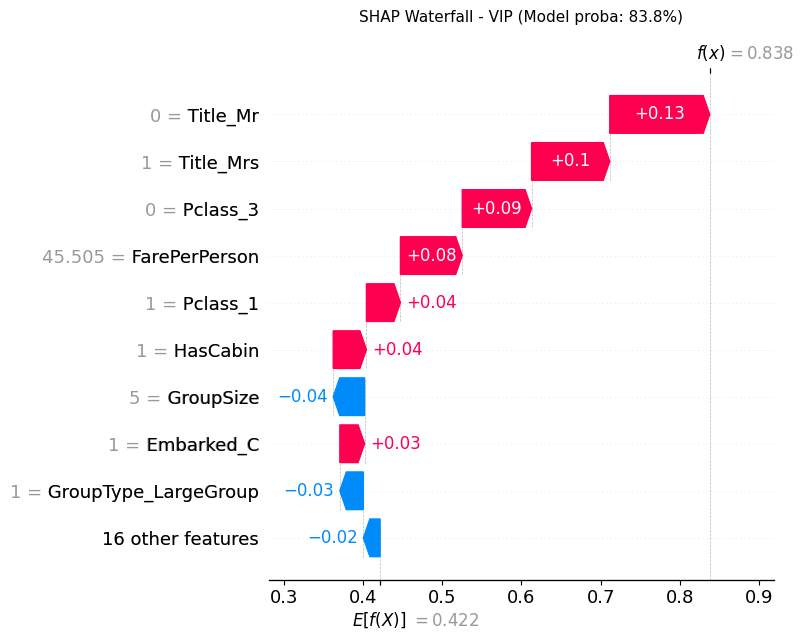

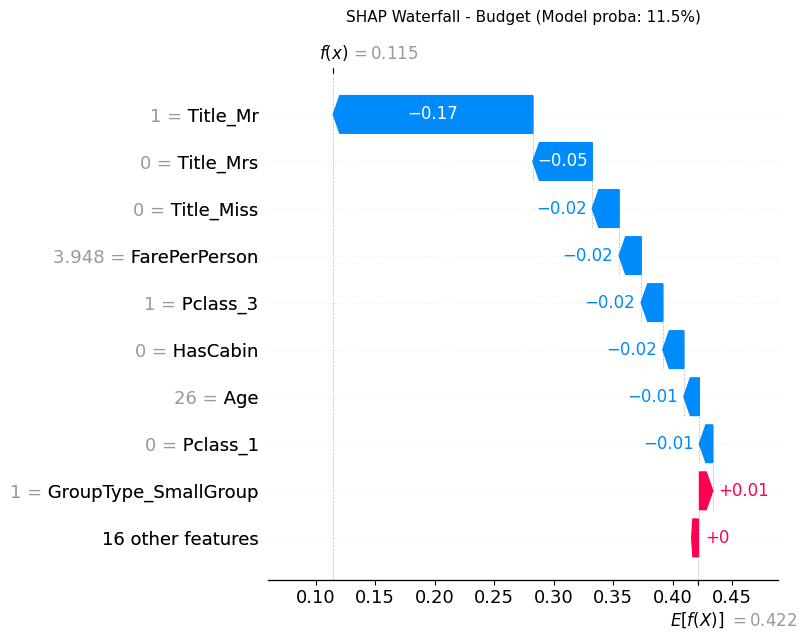

In [13]:
# 1. VIP Passenger
plt.figure(figsize=(9, 5))
shap.plots.waterfall(shap_vip[0], max_display=10, show=False)
plt.title(
    f"SHAP Waterfall - VIP (Model proba:"
    f" {response_vip['survival_probability']:.1%})",
    fontsize=11,
    pad=15,
)
plt.tight_layout()
plt.show()

# 2. Budget passenger
plt.figure(figsize=(9, 5))
shap.plots.waterfall(shap_budget[0], max_display=10, show=False)
plt.title(
    f"SHAP Waterfall - Budget (Model proba:"
    f" {response_budget['survival_probability']:.1%})",
    fontsize=11,
    pad=15,
)
plt.tight_layout()
plt.show()

### 7. Model Explainability & Decision Attribution (TreeSHAP)

Using SHAP waterfall attributions based on the background reference dataset ($E[f(X)] = 0.422$), we inspect the exact directional feature contributions driving individual model predictions:

#### Case 1: VIP Passenger (Madeleine Astor)
* **Model Output**: $f(x) = \mathbf{0.838}$ (Model probability: **83.8%**, baseline $E[f(X)] = 0.422$)
* **Positive Drivers (Lifting Survival Probability)**:
  * `Title_Mr = 0` ($+0.13$) and `Title_Mrs = 1` ($+0.10$): Absence of the adult male honorific combined with the married female status provides the largest cumulative push ($+0.23$).
  * `Pclass_3 = 0` ($+0.09$) and `Pclass_1 = 1` ($+0.04$): Explicit assignment to 1st class adds $+0.13$ in total socioeconomic advantage.
  * `FarePerPerson = 45.505` ($+0.08$): High per-capita ticket price strongly supports survival chance.
  * `HasCabin = 1` ($+0.04$) and `Embarked_C = 1` ($+0.03$): Proximity to private accommodations and boarding at Cherbourg provide additional positive shifts.
* **Negative Offsets (Penalizing Survival Probability)**:
  * `GroupSize = 5` ($-0.04$) and `GroupType_LargeGroup = 1` ($-0.03$): Ticket sharing across a larger traveling group acts as a slight drag on survival probability.
  * Remaining 16 features aggregate to a minor negative drift of $-0.02$.

#### Case 2: Budget Passenger (Johan Svensson)
* **Model Output**: $f(x) = \mathbf{0.115}$ (Model probability: **11.5%**, baseline $E[f(X)] = 0.422$)
* **Negative Drivers (Depressing Survival Probability)**:
  * `Title_Mr = 1` ($-0.17$): Being an adult male represents the single strongest penalty against survival.
  * `Title_Mrs = 0` ($-0.05$) and `Title_Miss = 0` ($-0.02$): Lack of female demographic indicators lowers the expected probability further.
  * Economic indicators: Low ticket price (`FarePerPerson = 3.948`, $-0.02$), 3rd class assignment (`Pclass_3 = 1`, $-0.02$, and `Pclass_1 = 0`, $-0.01$), and lack of assigned cabin (`HasCabin = 0`, $-0.02$).
  * Cohort age: Imputed median adult age (`Age = 26`, $-0.01$).
* **Positive Offsets**:
  * `GroupType_SmallGroup = 1` ($+0.01$): Minor upward correction, negligible against demographic and socioeconomic penalties.

In [14]:
df_test_raw = pd.read_csv('test.csv')

batch_results = prod_api.predict_batch(df_test_raw)

submission = batch_results[['PassengerId', 'Survived_Pred']].rename(
    columns={'Survived_Pred': 'Survived'}
)
submission.to_csv('submission.csv', index=False)
print(f'File submission.csv ready ({len(submission)} records).')

File submission.csv ready (418 records).


### 8. Batch Inference & Submission Generation

With the production-ready predictor bundle validated on individual profiles, we execute end-to-end batch scoring across the unseen Kaggle evaluation dataset (`test.csv`).

#### Vectorized Scoring Pipeline
* **Preserving Ingestion Context**: The batch inference method `predict_batch` processes all **418** test records through the frozen pipeline. It handles categorical encoding, aligns dummy columns to the training schema, and appends both positive-class probabilities (`Survival_Prob`) and thresholded binary classifications (`Survived_Pred` at `threshold=0.5`) without modifying the original input index.
* **Artifact Generation**: The output is formatted strictly into the required two-column schema (`PassengerId`, `Survived`) and serialized to `submission.csv`. This artifact is archived directly within the project repository as the reproducible output of the primary tree-ensemble pipeline.

In [15]:
# 1. Initialize tuner and run hyperparameter optimization for Logistic Regression
tuner_lr = TitanicOptunaTuner(
    df_raw=df_train_raw,
    target_col='Survived',
    n_splits=5,
    random_state=42,
)

print('Optuna tuning starting for Logistic Regression...')
study_lr = tuner_lr.tune(model_name='LogisticRegression', n_trials=40)

# 2. Extract best cross-validation score and optimal hyperparameters
best_score_lr = study_lr.best_value
best_lr_params = study_lr.best_params

print(f'\nBest 5-fold CV accuracy (Logistic Regression): {best_score_lr:.4f}')
print('Best hyperparameters found:')
for param, val in best_lr_params.items():
  print(f'  • {param}: {val}')

# Enforce deterministic training for reproducibility
best_lr_params['random_state'] = 42

# 3. Fit pipeline on full training dataset and extract linear feature set
final_pipeline_lr = TitanicDataPipeline()
final_pipeline_lr.fit(df_train_raw)

X_train_lin, _, _ = final_pipeline_lr.transform(df_train_raw, is_train=True)
y_train_full = df_train_raw['Survived'].values

# 4. Fit StandardScaler on full training linear features (critical for regularized linear models)
scaler_lr = StandardScaler()
X_train_lin_scaled = scaler_lr.fit_transform(X_train_lin)

# 5. Train final Logistic Regression estimator on scaled features
final_model_lr = LogisticRegression(**best_lr_params)
final_model_lr.fit(X_train_lin_scaled, y_train_full)

# 6. Execute sanity check comparing training metrics against cross-validation score
train_preds_lr = final_model_lr.predict(X_train_lin_scaled)
train_probs_lr = final_model_lr.predict_proba(X_train_lin_scaled)[:, 1]

print('\nSANITY CHECK (Logistic Regression)')
print(f'Train Accuracy: {accuracy_score(y_train_full, train_preds_lr):.4f}')
print(f'Train ROC-AUC:  {roc_auc_score(y_train_full, train_probs_lr):.4f}')
print('\nClassification Report (Train):')
print(
    classification_report(
        y_train_full,
        train_preds_lr,
        target_names=['Died', 'Survived'],
    )
)

# 7. Package into TitanicPredictor bundle and save as a standalone artifact
prod_predictor_lr = TitanicPredictor(
    model=final_model_lr,
    pipeline=final_pipeline_lr,
    scaler=scaler_lr,
    feature_set='linear',
    threshold=0.5,
)

prod_predictor_lr.save('titanic_lr_prod.joblib')

[I 2026-11-16 18:04:27,227] A new study created in memory with name: no-name-4b412bbc-b1be-4684-a610-d65b4226d6f7
[I 2026-11-16 18:04:27,322] Trial 0 finished with value: 0.7968238026489235 and parameters: {'C': 0.0074593432857265485, 'solver': 'lbfgs'}. Best is trial 0 with value: 0.7968238026489235.
[I 2026-11-16 18:04:27,417] Trial 1 finished with value: 0.8260247316552632 and parameters: {'C': 0.09846738873614563, 'solver': 'lbfgs'}. Best is trial 1 with value: 0.8260247316552632.


Optuna tuning starting for Logistic Regression...


[I 2026-11-16 18:04:27,512] Trial 2 finished with value: 0.6161634548992531 and parameters: {'C': 0.00019517224641449495, 'solver': 'lbfgs'}. Best is trial 1 with value: 0.8260247316552632.
[I 2026-11-16 18:04:27,606] Trial 3 finished with value: 0.8248885820099178 and parameters: {'C': 0.3470266988650412, 'solver': 'liblinear'}. Best is trial 1 with value: 0.8260247316552632.
[I 2026-11-16 18:04:27,708] Trial 4 finished with value: 0.8271357730211537 and parameters: {'C': 1.452824663751602, 'solver': 'lbfgs'}. Best is trial 4 with value: 0.8271357730211537.
[I 2026-11-16 18:04:27,800] Trial 5 finished with value: 0.7676542589919026 and parameters: {'C': 0.0008260808399079611, 'solver': 'liblinear'}. Best is trial 4 with value: 0.8271357730211537.
[I 2026-11-16 18:04:27,899] Trial 6 finished with value: 0.8305065595380077 and parameters: {'C': 0.01444525102276306, 'solver': 'liblinear'}. Best is trial 6 with value: 0.8305065595380077.
[I 2026-11-16 18:04:27,992] Trial 7 finished with v


Best 5-fold CV accuracy (Logistic Regression): 0.8339
Best hyperparameters found:
  • C: 0.020498540113047532
  • solver: lbfgs

SANITY CHECK (Logistic Regression)
Train Accuracy: 0.8395
Train ROC-AUC:  0.8717

Classification Report (Train):
              precision    recall  f1-score   support

        Died       0.85      0.90      0.87       549
    Survived       0.83      0.74      0.78       342

    accuracy                           0.84       891
   macro avg       0.84      0.82      0.83       891
weighted avg       0.84      0.84      0.84       891

Artifact saved at titanic_lr_prod.joblib


### 9. Multi-Model Pipeline Portability: Logistic Regression Baseline

To prove that the modular pipeline architecture is genuinely model-agnostic and supports divergent model paradigms, we tune and serialize a production bundle for regularized **Logistic Regression** (`titanic_lr_prod.joblib`).

#### Optimization & Matrix Routing
* **Bayesian Hyperparameter Search**: Using `TitanicOptunaTuner`, we optimize the inverse regularization strength $C$ over a logarithmic space ($10^{-4}$ to $10.0$) alongside solver selection (`lbfgs` vs. `liblinear`).
* **Optimal Linear Configuration**:
  * `Best 5-Fold CV Accuracy`: **83.39%**
  * `Optimal Parameters`: `C = 0.0205`, `solver = 'lbfgs'`
  * *Diagnostics*: Setting $C \approx 0.02$ applies substantial $L_2$ shrinkage, pulling smaller dummy coefficients toward zero and preventing over-reliance on noisy category levels.

#### End-to-End Pipeline Cohesion
* **Automatic Feature Routing**: Unlike Random Forest (which utilized the 25-feature unscaled `trees` matrix), the linear pipeline switches to the 20-feature `linear` set—automatically dropping reference dummy levels (`Pclass_1`, `Title_Mr`, `GroupType_Alone`, `Embarked_S`, `Deck_U`) to prevent the dummy variable trap.
* **Integrated Scale Encapsulation**: A dedicated `StandardScaler` is fitted on the full linear training matrix and bundled alongside the estimator in `TitanicPredictor(..., feature_set='linear', scaler=scaler_lr)`. 
* **Operational Equivalency**: When loaded in production, `TitanicPredictor` autonomously detects the `linear` flag, extracts the proper 20-column matrix, transforms raw features through the saved scaler, and evaluates probabilities without any manual data preprocessing required from the consumer.

#### Train vs. CV Generalization Audit
* **Train Accuracy**: **83.95%** (vs. **83.39%** CV)
* **Train ROC-AUC**: **0.8717**
* *Conclusion*: The negligible gap between training accuracy (**83.95%**) and cross-validation accuracy (**83.39%**) highlights an exceptionally well-generalized, low-variance linear baseline. It demonstrates that our feature engineering layer produces high-signal representations suitable for both complex non-linear ensembles and strict linear decision boundaries.